# TuniShop — 05. EDA Stock et logistique : livraison, entrepôts, stock, fournisseurs

**Auteure :** Sarra Abdeljaouad · **Source :** TuniShop_DWH, lecture directe des vues `bi` (SQL Server) · **Période :** 01/01/2023 – 31/12/2025

**Objectif :** mesurer la qualité de la livraison, le rôle des entrepôts, la tenue du stock et la ponctualité des fournisseurs.

| N° (Plan_Analyse_EDA) | Question |
|---|---|
| Q13 | Les livraisons arrivent-elles à l'heure ? Qui est en retard ? |
| Q14 | Quel est le rôle des entrepôts ? Combien de colis n'arrivent jamais ? |
| Q19 | Le stock suit-il la demande ? Quand les ruptures arrivent-elles ? |
| Q20 | Quels mouvements font vivre le stock ? |
| Q21 | Les fournisseurs livrent-ils à temps ? La fiabilité annoncée est-elle tenue ? |

Pour chaque question : un tableau rappelle l'**hypothèse** du plan d'analyse, les **vues** utilisées et la **méthode** ; puis viennent le calcul (cellules **🔗 SQL direct** exécutées par SQL Server, et pandas), le graphique, la **lecture** et le **verdict** de l'hypothèse (✅ confirmée, 🟡 nuancée, ❌ infirmée).

Les figures sont enregistrées dans `06_Exports/Figures` et les tableaux de résultats dans `06_Exports/Tables` : ils alimentent les rapports de `04_Livrables/EDA`.

## 0. Connexion au DWH et chargement

Le notebook lit les 23 vues `bi.v_*` **en direct** dans SQL Server (réglages dans `00_Commun/tunishop_analytics/config.py`), puis vérifie qu'il s'agit bien du DWH validé.

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun, à côté de ce dossier)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, validation, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)      # messages de version sans intérêt ici
cfg.appliquer_style()

# --- Raccourcis
sql = chargement.requete                                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

In [2]:
chargement.ouvrir_connexion()
vues, p = chargement.charger_donnees(source="dwh")

# Raccourcis vers les tables préparées
cmd, lig, liv, avis, rmb, pai = p["cmd"], p["lig"], p["liv"], p["avis"], p["rmb"], p["pai"]

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
Lecture directe des vues bi.v_* — 13/11/2026 23:42
  v_dim_date                        1 828 lignes


  v_dim_client                     16 002 lignes
  v_dim_produit                     1 603 lignes
  v_dim_fournisseur                    42 lignes
  v_dim_geographie                     26 lignes
  v_dim_entrepot                        5 lignes
  v_dim_transporteur                    6 lignes
  v_dim_campagne                      154 lignes
  v_dim_coupon                         70 lignes
  v_dim_canal                           8 lignes
  v_dim_mode_paiement                   7 lignes
  v_dim_statut_commande                10 lignes
  v_dim_motif_retour                   14 lignes


  v_fact_ventes                   115 903 lignes


  v_fact_commandes                 66 268 lignes


  v_fact_paiements                 64 491 lignes


  v_fact_livraisons                61 793 lignes


  v_fact_remboursements             8 815 lignes
  v_fact_avis                       9 314 lignes
  v_fact_marketing_quotidien        3 427 lignes


  v_fact_achats_fournisseur        11 793 lignes


  v_fact_mouvements_stock         140 184 lignes


  v_fact_stock_mensuel             56 562 lignes


In [3]:
# Point de départ contrôlé : 5 totaux, valeur validée (PV) = calcul SQL = calcul Python ? (attendu : OK partout)
validation.verifier_coherence(p)

,controle,indicateur,valide_pv,sql_vues_bi,python_pandas,statut
0,C03,Lignes de vente,115 903.000,115 903.000,115 903.000,OK
1,C04,Commandes,66 268.000,66 268.000,66 268.000,OK
2,C05,Livraisons,61 793.000,61 793.000,61 793.000,OK
3,C06,CA reconnu TTC (DT),15 541 665.655,15 541 665.655,15 541 665.655,OK
4,C07,Clients ayant commandé (hors membre inconnu),12 472.000,12 472.000,12 472.000,OK


### Q13. Les livraisons arrivent-elles à l'heure ? Qui est en retard ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les transporteurs sont inégaux ; SahelLog se dégrade à partir du 01/07/2024 (contrôles CC11 à CC13). |
| **Indicateurs** | Délai de livraison, taux de retard par transporteur et semestre |
| **Vues bi utilisées** | `v_fact_livraisons`, `v_dim_transporteur` |
| **Méthode** | pandas |
| **Visualisation** | Histogramme ; carte de chaleur |
| **Lien data mining / ML** | Retard : cible et variable transporteur |

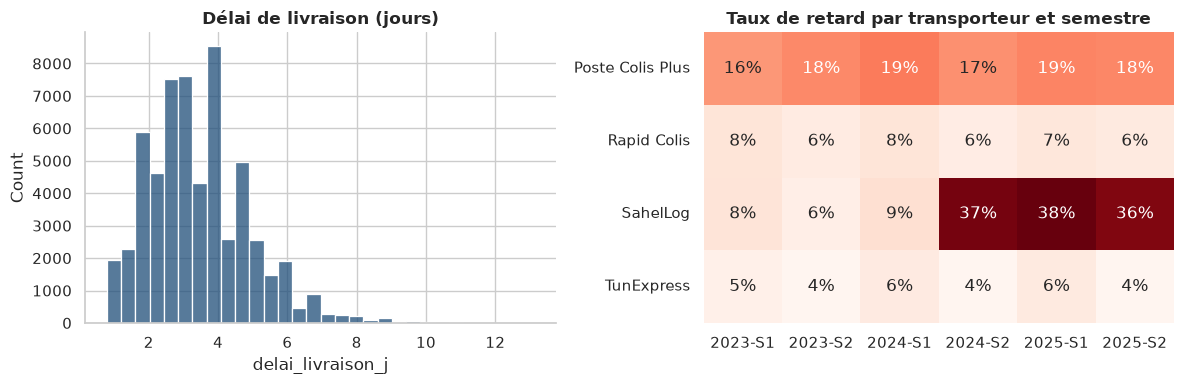

In [4]:
livrees = liv[liv["est_livree"]].copy()
livrees["en_retard"] = (livrees["retard_j"].fillna(0) > 0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(livrees["delai_livraison_j"], bins=30, ax=axes[0], color=cfg.BLEU)
axes[0].set_title("Délai de livraison (jours)")
taux = livrees.pivot_table(index="transporteur", columns="semestre", values="en_retard", aggfunc="mean")
sns.heatmap(taux, annot=True, fmt=".0%", cmap="Reds", cbar=False, ax=axes[1])
axes[1].set_title("Taux de retard par transporteur et semestre"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); montrer("Q13_1")

In [5]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(taux, "Q13_retard_transporteur_semestre")
print("Tableaux exportés.")

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.eda_q13_retard_transporteur_semestre          4 lignes
Tableaux exportés.


> **Lecture.** Le délai de livraison médian est de 3,2 jours (75 % des colis arrivent en moins de 4,2 jours). Les transporteurs sont très inégaux : Rapid Colis et TunExpress restent entre 5 et 7 % de retards, Poste Colis Plus autour de 18 %, et **SahelLog se dégrade à partir du 2nd semestre 2024** (de 8,5 % à plus de 37 %), le scénario déjà constaté dans les cubes (contrôles CC11 et CC12). **Pour le ML :** le transporteur sera la variable principale du modèle de retard, mais son effet change dans le temps.

> ✅ **Verdict : hypothèse confirmée** — SahelLog passe d'environ 8 % à plus de 37 % de retards après le 01/07/2024.

### Q14. Quel est le rôle des entrepôts ? Combien de colis n'arrivent jamais ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les entrepôts ont des performances différentes ; une partie des colis revient à l'expéditeur après plusieurs tentatives. |
| **Indicateurs** | Expéditions, taux de non-livraison, préparation, délai, taux de retard par entrepôt ; statuts et tentatives ; transporteurs par entrepôt |
| **Vues bi utilisées** | `v_fact_livraisons`, `v_dim_entrepot`, `v_dim_transporteur` |
| **Méthode** | SQL direct + pandas |
| **Visualisation** | Tableaux ; courbes par année |
| **Lien data mining / ML** | Retard : variable entrepôt (liens avec le transporteur) |

,expeditions,taux_non_livree,preparation_moy_h,delai_livraison_moy_j,taux_retard
nom_entrepot,,,,,
Entrepôt Grand Tunis,31294,0.046,19.946,3.208,0.129
Entrepôt Sahel,16161,0.050,19.859,3.496,0.134
Entrepôt Sud,14338,0.054,19.883,3.929,0.195


,statut_livraison,expeditions,tentatives_moy
0,livree,58776,1.138
1,echec_retour_expediteur,2756,2.487
2,en_transit,211,NaN
3,en_preparation,50,NaN


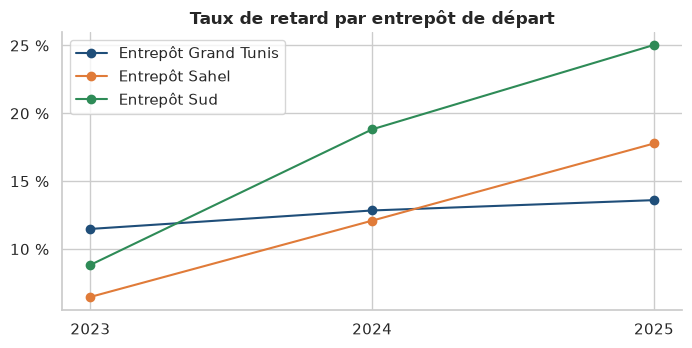

transporteur,Poste Colis Plus,Rapid Colis,SahelLog,TunExpress
nom_entrepot,,,,
Entrepôt Grand Tunis,0.349,0.345,0.050,0.255
Entrepôt Sahel,0.204,0.248,0.394,0.153
Entrepôt Sud,0.297,0.209,0.495,0.000


In [6]:
# 🔗 SQL direct — expéditions, échecs, préparation, délai et retard par entrepôt
entrepots = sql("""
    SELECT e.nom_entrepot,
           COUNT(*)                                                                AS expeditions,
           1.0 * SUM(CASE WHEN l.est_livree = 1 THEN 0 ELSE 1 END) / COUNT(*)      AS taux_non_livree,
           AVG(1.0 * l.delai_preparation_h)                                         AS preparation_moy_h,
           AVG(CASE WHEN l.est_livree = 1 THEN 1.0 * l.delai_livraison_j END)       AS delai_livraison_moy_j,
           1.0 * SUM(CASE WHEN l.retard_j > 0 THEN 1 ELSE 0 END)
               / NULLIF(SUM(CASE WHEN l.est_livree = 1 THEN 1 ELSE 0 END), 0)       AS taux_retard
    FROM bi.v_fact_livraisons l
    JOIN bi.v_dim_entrepot e ON e.entrepot_sk = l.entrepot_sk
    GROUP BY e.nom_entrepot
    ORDER BY taux_retard
""").set_index("nom_entrepot")
display(entrepots)

# 🔗 SQL direct — statuts de livraison et nombre de tentatives
display(sql("""
    SELECT l.statut_livraison, COUNT(*) AS expeditions, AVG(1.0 * l.nb_tentatives) AS tentatives_moy
    FROM bi.v_fact_livraisons l
    GROUP BY l.statut_livraison
    ORDER BY expeditions DESC
"""))

# Taux de retard par entrepôt et par année (pandas)
ent = vues["dim_entrepot"][["entrepot_sk", "nom_entrepot"]]
l_ent = livrees.merge(ent, on="entrepot_sk")
ax = l_ent.pivot_table(index="annee", columns="nom_entrepot", values="en_retard", aggfunc="mean").plot(marker="o", figsize=(8, 3.6))
ax.set_title("Taux de retard par entrepôt de départ"); cfg.format_pourcent(ax); ax.set_xticks([2023, 2024, 2025])
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.set_xlabel(""); ax.legend(title=""); montrer("Q14_1")

# Quels transporteurs partent de chaque entrepôt ? (part des expéditions livrées)
pd.crosstab(l_ent["nom_entrepot"], l_ent["transporteur"], normalize="index")

In [7]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(entrepots, "Q14_entrepots")
print("Tableaux exportés.")

  ✔ ana.eda_q14_entrepots                             3 lignes
Tableaux exportés.


> **Lecture.** L'**Entrepôt Sud** a nettement plus de retards (19,5 % contre 13 % ailleurs) et un délai plus long (3,9 jours contre 3,2), alors que le temps de préparation est **identique** dans les 3 entrepôts (environ 20 heures). Son taux de retard passe de 9 % à 25 % entre 2023 et 2025. L'explication est dans le tableau des transporteurs : l'Entrepôt Sud expédie **49 % de ses colis par SahelLog** et aucun par TunExpress, contre 5 % de SahelLog pour le Grand Tunis. Côté échecs : 2 756 colis (4,5 %) reviennent à l'expéditeur après 2,5 tentatives en moyenne. **Pour le ML :** entrepôt et transporteur sont liés ; le modèle de retard pourra attribuer à l'entrepôt un effet qui vient en réalité de SahelLog. On regardera l'importance des variables avec cette prudence.

> 🟡 **Verdict : hypothèse nuancée** — l'Entrepôt Sud a plus de retards, mais surtout parce qu'il expédie 49 % de ses colis par SahelLog ; 4,5 % des colis reviennent à l'expéditeur.

### Q19. Le stock suit-il la demande ? Quand les ruptures arrivent-elles ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les ruptures sont plus fréquentes aux pics de vente. |
| **Indicateurs** | Taux de rupture et valeur du stock par fin de mois, par mois de l'année et par catégorie |
| **Vues bi utilisées** | `v_fact_stock_mensuel`, `v_dim_date`, `v_dim_produit` |
| **Méthode** | SQL direct + pandas |
| **Visualisation** | Courbes mensuelles ; tableau |
| **Lien data mining / ML** | Prévision : intérêt pour l'approvisionnement |

La vue `v_fact_stock_mensuel` est une **photo de fin de mois** par produit et entrepôt : on ne l'additionne pas dans le temps (on compare les mois entre eux).

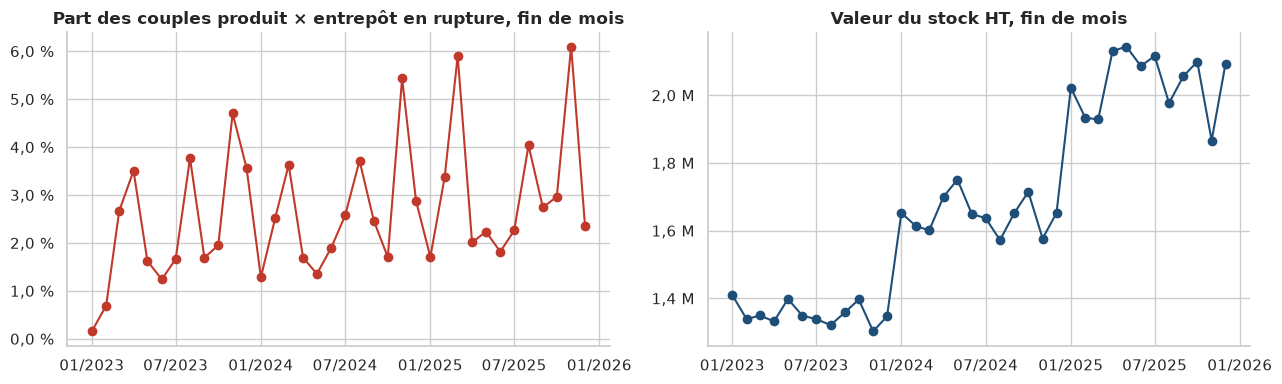

mois,1,2,3,4,5,6,7,8,9,10,11,12
taux de rupture moyen,0.010,0.022,0.041,0.024,0.017,0.017,0.022,0.038,0.023,0.022,0.054,0.029


,taux_rupture,valeur_stock_fin_2025
categorie,,
Électroménager,0.036,424 044.987
Beauté & Santé,0.036,70 459.391
Bébé & Enfants,0.034,37 846.133
Maison & Cuisine,0.029,71 953.208
Épicerie fine,0.028,21 020.442
Mode,0.024,130 925.391
Électronique & High-Tech,0.023,1 255 364.488
Fournitures & Livres,0.019,25 342.105
Sport & Loisirs,0.017,56 418.551


In [8]:
# 🔗 SQL direct — taux de rupture et valeur du stock à chaque fin de mois
stock_mois = sql("""
    SELECT d.annee_mois,
           1.0 * SUM(CASE WHEN s.est_rupture = 1 THEN 1 ELSE 0 END) / COUNT(*) AS taux_rupture,
           SUM(s.valeur_stock_ht)                                              AS valeur_stock_ht
    FROM bi.v_fact_stock_mensuel s
    JOIN bi.v_dim_date d ON d.date_sk = s.date_sk
    GROUP BY d.annee_mois
    ORDER BY d.annee_mois
""")
stock_mois["mois"] = pd.to_datetime(stock_mois["annee_mois"].str.strip())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(stock_mois["mois"], stock_mois["taux_rupture"], marker="o", color=cfg.ROUGE)
axes[0].set_title("Part des couples produit × entrepôt en rupture, fin de mois"); cfg.format_pourcent(axes[0], decimales=1)
axes[1].plot(stock_mois["mois"], stock_mois["valeur_stock_ht"], marker="o", color=cfg.BLEU)
axes[1].set_title("Valeur du stock HT, fin de mois"); cfg.format_millions(axes[1])
for ax in axes:                                    # une étiquette tous les 6 mois, au format 01/2024
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
plt.tight_layout(); montrer("Q19_1")

# Taux de rupture moyen par mois de l'année : les ruptures tombent-elles aux pics de vente ?
display(stock_mois.groupby(stock_mois["mois"].dt.month)["taux_rupture"].mean().to_frame("taux de rupture moyen").T)

stk = p["stk"]
stk.groupby("categorie").agg(taux_rupture=("est_rupture", "mean")).join(
    stk[stk["date_sk"] == stk["date_sk"].max()].groupby("categorie")["valeur_stock_ht"].sum().rename("valeur_stock_fin_2025")
).sort_values("taux_rupture", ascending=False)

In [9]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(stock_mois, "Q19_stock_mensuel")
print("Tableaux exportés.")

  ✔ ana.eda_q19_stock_mensuel                        36 lignes
Tableaux exportés.


> **Lecture.** Le taux de rupture augmente doucement (2,3 % des couples produit × entrepôt en 2023, 2,6 % en 2024, 3,1 % en 2025) et surtout, il **suit les pics de vente** : 5,4 % en moyenne fin novembre (Black Friday, 6,1 % en 2025), 4,1 % fin mars (Ramadan et Aïd) et 3,8 % fin août, contre environ 2 % les autres mois. La valeur du stock passe de 1,41 à 2,09 M DT (+48 %) avec la croissance, et l'Électronique en représente 60 % fin 2025. **Pour le ML :** c'est un argument concret pour la **prévision des ventes** (cas n° 3) : anticiper les pics éviterait des ruptures, et donc une partie des remboursements pour rupture.

> ✅ **Verdict : hypothèse confirmée** — taux de rupture de 5,4 % fin novembre, 4,1 % fin mars, environ 2 % les autres mois.

### Q20. Quels mouvements font vivre le stock ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les ventes et les réceptions dominent ; les retours non revendables correspondent aux mises au rebut. |
| **Indicateurs** | Mouvements, quantités et valeur par type et par sens |
| **Vues bi utilisées** | `v_fact_mouvements_stock` |
| **Méthode** | SQL direct |
| **Visualisation** | Tableau |
| **Lien data mining / ML** | Contexte (cohérence des flux) |

In [10]:
# 🔗 SQL direct — mouvements de stock par type et par sens (E = entrée, S = sortie)
sql("""
    SELECT m.type_mouvement, m.sens,
           COUNT(*)          AS mouvements,
           SUM(m.quantite)   AS quantite,
           SUM(m.valeur_ht)  AS valeur_ht
    FROM bi.v_fact_mouvements_stock m
    GROUP BY m.type_mouvement, m.sens
    ORDER BY mouvements DESC
""")

,type_mouvement,sens,mouvements,quantite,valeur_ht
0,vente,S,110228,-164188,-9 750 545.198
1,reception_fournisseur,E,11539,148956,8 425 315.533
2,retour_client,E,6182,7329,438 472.752
3,retour_echec_livraison,E,4836,6411,394 755.475
4,annulation_commande,E,3827,5513,355 561.684
5,stock_initial,E,1788,14892,2 118 740.260
6,mise_au_rebut,S,617,-749,-52 141.372
7,retour_client_non_revendable,E,617,749,52 141.372
8,ajustement_inventaire,S,453,-897,-124 521.665
9,ajustement_inventaire,E,97,140,13 974.570


> **Lecture.** Le stock vit surtout des **ventes** (110 228 sorties, 164 188 unités) et des **réceptions fournisseurs** (148 956 unités), plus un stock initial de 14 892 unités. Les retours remettent 7 329 unités revendables en stock. Le contrôle de cohérence est bon : les **749 unités non revendables** retournées correspondent exactement aux **749 unités mises au rebut**. Les ajustements d'inventaire font perdre 757 unités nettes (environ 110 000 DT HT).

> ✅ **Verdict : hypothèse confirmée** — les 749 unités retournées non revendables correspondent aux 749 unités mises au rebut.

### Q21. Les fournisseurs livrent-ils à temps ? La fiabilité annoncée est-elle tenue ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | L'import est plus long que le local ; la fiabilité annoncée ne reflète pas les retards réels (scénario FRN025 au T2 2024, contrôle CC16). |
| **Indicateurs** | Délai moyen, taux et durée de retard par pays ; fiabilité annoncée contre retard constaté par fournisseur |
| **Vues bi utilisées** | `v_fact_achats_fournisseur`, `v_dim_fournisseur` |
| **Méthode** | SQL direct + pandas |
| **Visualisation** | Tableau ; nuage de points |
| **Lien data mining / ML** | Cas ML bonus possible : retard fournisseur |

,pays,origine,lignes_recues,delai_moy_j,taux_retard,retard_moy_j
0,Tunisie,local,7880,7.541,0.437,1.552
1,Espagne,import,215,22.349,0.493,2.312
2,Italie,import,361,31.457,0.452,2.114
3,Chine,import,2054,34.772,0.522,3.753
4,Turquie,import,581,39.589,0.513,3.363
5,France,import,448,42.629,0.498,3.333


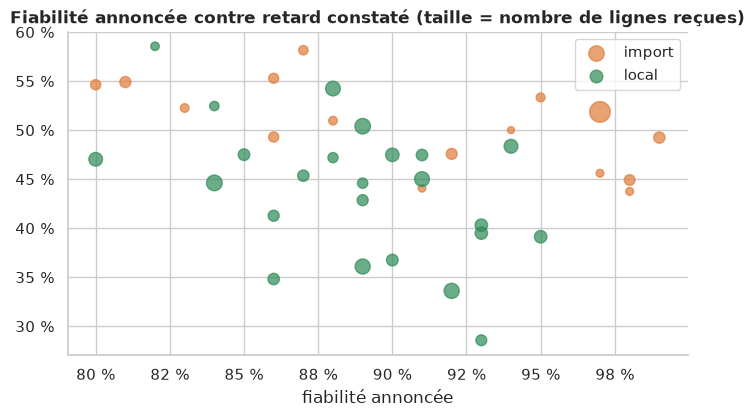

Corrélation fiabilité annoncée / taux de retard : -0.32


,lignes,taux_retard,fiabilite_annoncee,local
nom_fournisseur,,,,
Sousse Shoes,152,0.586,0.820,True
Yiwu Global Toys,184,0.582,0.870,False
Ankara Beyaz Eşya,208,0.553,0.860,False
Ningbo Accessories Co.,255,0.549,0.810,False
Dongguan Climatech,216,0.546,0.800,False
Hammamet Linge,448,0.542,0.880,True
Marseille Cosmétiques,165,0.533,0.950,False
Bizerte Plast,183,0.525,0.840,True


In [11]:
# 🔗 SQL direct — délai et retard d'approvisionnement par pays (lignes reçues uniquement)
fournisseurs_pays = sql("""
    SELECT f.pays,
           CASE WHEN f.est_local = 1 THEN 'local' ELSE 'import' END                       AS origine,
           COUNT(*)                                                                     AS lignes_recues,
           AVG(1.0 * a.delai_appro_reel_j)                                               AS delai_moy_j,
           1.0 * SUM(CASE WHEN a.retard_appro_j > 0 THEN 1 ELSE 0 END) / COUNT(*)        AS taux_retard,
           AVG(1.0 * a.retard_appro_j)                                                   AS retard_moy_j
    FROM bi.v_fact_achats_fournisseur a
    JOIN bi.v_dim_fournisseur f ON f.fournisseur_sk = a.fournisseur_sk
    WHERE a.date_reception_sk > 0
    GROUP BY f.pays, f.est_local
    ORDER BY delai_moy_j
""")
display(fournisseurs_pays)

# Fiabilité annoncée (dimension fournisseur) contre taux de retard réellement constaté
ach = p["ach"]
recues = ach[ach["date_reception_sk"] > 0].merge(
    vues["dim_fournisseur"][["fournisseur_sk", "fiabilite_livraison", "est_local"]], on="fournisseur_sk")
par_fournisseur = recues.groupby("nom_fournisseur").agg(
    lignes=("ligne_cf_id", "count"), taux_retard=("retard_appro_j", lambda s: (s > 0).mean()),
    fiabilite_annoncee=("fiabilite_livraison", "first"), local=("est_local", "first"))

fig, ax = plt.subplots(figsize=(8, 4.2))
for local, g in par_fournisseur.groupby("local"):
    ax.scatter(g["fiabilite_annoncee"], g["taux_retard"], s=g["lignes"] / 4, alpha=0.7,
               color=cfg.VERT if local else cfg.ORANGE, label="local" if local else "import")
ax.set_title("Fiabilité annoncée contre retard constaté (taille = nombre de lignes reçues)")
ax.set_xlabel("fiabilité annoncée"); cfg.format_pourcent(ax); cfg.format_pourcent(ax, "x"); ax.legend()
montrer("Q21_1")
print("Corrélation fiabilité annoncée / taux de retard :",
      round(par_fournisseur["fiabilite_annoncee"].corr(par_fournisseur["taux_retard"]), 2))
par_fournisseur.sort_values("taux_retard", ascending=False).head(8)

In [12]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(fournisseurs_pays, "Q21_fournisseurs_pays")
cfg.exporter_table(par_fournisseur, "Q21_fournisseurs")
print("Tableaux exportés.")

  ✔ ana.eda_q21_fournisseurs_pays                     6 lignes
  ✔ ana.eda_q21_fournisseurs                         40 lignes
Tableaux exportés.


In [13]:
# Scénario du fournisseur FRN025 (contrôle CC16 de la phase BI) : retard moyen par trimestre de commande
frn025 = p["ach"][(p["ach"]["fournisseur_id"] == "FRN025") & (p["ach"]["date_reception_sk"] > 0)]
frn025.groupby("trimestre")["retard_appro_j"].agg(lignes_recues="size", retard_moyen_j="mean").T

trimestre,2023-T1,2023-T2,2023-T3,2023-T4,2024-T1,2024-T2,2024-T3,2024-T4,2025-T1,2025-T2,2025-T3,2025-T4
lignes_recues,61.000,81.000,65.000,77.000,66.000,51.000,76.000,101.000,83.000,54.000,91.000,81.000
retard_moyen_j,2.492,3.074,3.754,2.247,2.924,32.137,6.566,2.485,2.253,2.852,2.209,1.679


> **Lecture.** Les fournisseurs tunisiens livrent en 7,5 jours en moyenne, les fournisseurs étrangers en 22 (Espagne) à 43 jours (France). Mais le **taux de retard est élevé partout** : 44 % des lignes locales et 45 à 52 % des lignes importées arrivent après la date prévue (retard moyen de 1,6 jour en local, 2 à 3,8 jours à l'import). La **fiabilité annoncée** dans la fiche fournisseur ne prévoit presque rien (corrélation de -0,32 avec le retard constaté) : Marseille Cosmétiques, annoncé fiable à 95 %, est en retard sur 53 % de ses lignes. **Pour la suite :** pour les achats, on se fiera à l'historique réel du DWH plutôt qu'à la fiche ; un modèle de retard fournisseur serait un cas ML bonus possible. Le scénario du fournisseur **FRN025** est bien visible : 32 jours de retard moyen sur les lignes commandées au 2e trimestre 2024, contre 2 à 7 jours les autres trimestres (34 jours par bon de commande, la valeur du contrôle CC16).

> ✅ **Verdict : hypothèse confirmée** — local 7,5 jours contre 22 à 43 à l'import ; fiabilité annoncée peu liée au retard réel (r = -0,32) ; FRN025 au T2 2024 bien visible.

## Synthèse du notebook

| N° | Question | Verdict | Constat clé |
|---|---|---|---|
| Q13 | Les livraisons arrivent-elles à l'heure ? Qui est en retard ? | ✅ Confirmée | SahelLog passe d'environ 8 % à plus de 37 % de retards après le 01/07/2024. |
| Q14 | Quel est le rôle des entrepôts ? Combien de colis n'arrivent jamais ? | 🟡 Nuancée | l'Entrepôt Sud a plus de retards, mais surtout parce qu'il expédie 49 % de ses colis par SahelLog ; 4,5 % des colis reviennent à l'expéditeur. |
| Q19 | Le stock suit-il la demande ? Quand les ruptures arrivent-elles ? | ✅ Confirmée | taux de rupture de 5,4 % fin novembre, 4,1 % fin mars, environ 2 % les autres mois. |
| Q20 | Quels mouvements font vivre le stock ? | ✅ Confirmée | les 749 unités retournées non revendables correspondent aux 749 unités mises au rebut. |
| Q21 | Les fournisseurs livrent-ils à temps ? La fiabilité annoncée est-elle tenue ? | ✅ Confirmée | local 7,5 jours contre 22 à 43 à l'import ; fiabilité annoncée peu liée au retard réel (r = -0,32) ; FRN025 au T2 2024 bien visible. |

**Ce que ce notebook transmet à la suite :**

- **Retard de livraison** : le transporteur est le facteur principal mais son effet change en 2025 (SahelLog) ; entrepôt et transporteur sont liés.
- **Demande** : les ruptures tombent aux pics de vente → la prédiction de la demande par produit sert directement l'approvisionnement.
- **Fournisseurs** : se fier à l'historique réel du DWH plutôt qu'à la fiabilité annoncée.

In [14]:
# Verdicts des hypothèses de ce notebook, enregistrés comme les autres résultats :
#   -> 06_Exports/Tables/EDA_hypotheses_05_EDA_Stock_Logistics.csv
#   -> table ana.eda_hypotheses de TuniShop_ANALYTICS (lignes de ce notebook seulement, colonne « notebook »)
verdicts = pd.DataFrame([["Q13", "Livraison et satisfaction", "Les livraisons arrivent-elles à l'heure ? Qui est en retard ?", "Les transporteurs sont inégaux ; SahelLog se dégrade à partir du 01/07/2024 (contrôles CC11 à CC13).", "Confirmée", "SahelLog passe d'environ 8 % à plus de 37 % de retards après le 01/07/2024."], ["Q14", "Livraison et satisfaction", "Quel est le rôle des entrepôts ? Combien de colis n'arrivent jamais ?", "Les entrepôts ont des performances différentes ; une partie des colis revient à l'expéditeur après plusieurs tentatives.", "Nuancée", "l'Entrepôt Sud a plus de retards, mais surtout parce qu'il expédie 49 % de ses colis par SahelLog ; 4,5 % des colis reviennent à l'expéditeur."], ["Q19", "Stock et fournisseurs", "Le stock suit-il la demande ? Quand les ruptures arrivent-elles ?", "Les ruptures sont plus fréquentes aux pics de vente.", "Confirmée", "taux de rupture de 5,4 % fin novembre, 4,1 % fin mars, environ 2 % les autres mois."], ["Q20", "Stock et fournisseurs", "Quels mouvements font vivre le stock ?", "Les ventes et les réceptions dominent ; les retours non revendables correspondent aux mises au rebut.", "Confirmée", "les 749 unités retournées non revendables correspondent aux 749 unités mises au rebut."], ["Q21", "Stock et fournisseurs", "Les fournisseurs livrent-ils à temps ? La fiabilité annoncée est-elle tenue ?", "L'import est plus long que le local ; la fiabilité annoncée ne reflète pas les retards réels (scénario FRN025 au T2 2024, contrôle CC16).", "Confirmée", "local 7,5 jours contre 22 à 43 à l'import ; fiabilité annoncée peu liée au retard réel (r = -0,32) ; FRN025 au T2 2024 bien visible."]],
                        columns=["question", "theme", "question_metier", "hypothese", "verdict", "constat"])
cfg.exporter_table(verdicts, "EDA_hypotheses_05_EDA_Stock_Logistics", index=False)
verdicts[["question", "verdict"]]

  ✔ ana.eda_hypotheses                                5 lignes


,question,verdict
0,Q13,Confirmée
1,Q14,Nuancée
2,Q19,Confirmée
3,Q20,Confirmée
4,Q21,Confirmée


In [15]:
# Fin du notebook : on ferme les connexions (DWH et base des résultats)
chargement.fermer_connexion()
publication.fermer_connexion()

Connexion fermée.
